# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북의 목표는 그래프를 많이 만드는 것이 아닙니다. **분석 질문에 맞는 그래프를 선택하고, 그래프에 들어간 데이터 범위와 수치를 검증하며, 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분하는 것**이 핵심입니다.

금액성 그래프는 기본적으로 `order_status == "completed"` 범위를 사용합니다. `line_total`은 주문 상세 한 행의 `quantity × unit_price`이며 회계상 순매출로 단정하지 않습니다.

## 0. 사용 방법

- 위에서부터 차례대로 실행합니다.
- 입력은 Chapter 05에서 만든 `data/processed/*_clean.csv`입니다.
- 파일이 없다면 프로젝트 루트에서 `python scripts/preprocess_data.py`를 먼저 실행합니다.
- 그래프를 보기 전에 **시각화용 집계 검증표**를 먼저 확인합니다.
- 대표 그래프마다 `관찰 → 해석 → 한계 → 다음 질문`을 Markdown 셀에 직접 작성합니다.
- 실제 실행 결과 숫자를 보고 작성하며 강의안의 예시를 정답처럼 사용하지 않습니다.

## 1. 질문에 맞는 그래프를 먼저 고릅니다

| 분석 질문 | 그래프 | 데이터 범위 |
| --- | --- | --- |
| 카테고리별 완료 주문 금액은 어떻게 다른가? | 막대그래프 | completed 주문 상세 |
| 월별 완료 주문 금액은 어떻게 변하는가? | 선그래프 | completed + 유효한 주문일 |
| 상품 가격은 어느 구간에 몰려 있는가? | 히스토그램 | 전체 상품 마스터 |
| 상품 가격과 완료 주문 판매 수량은 어떤 패턴인가? | 산점도 | completed 상품 집계 |
| 완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가? | 가로 막대그래프 | completed 고객 집계 |
| 주문 상태별 주문 수는 어떻게 다른가? | 막대그래프 | 전체 orders |

> 그래프 종류보다 먼저 **질문과 데이터 범위**를 고정합니다.

In [1]:
from pathlib import Path
import sys

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("현재 실행 위치:", CURRENT_DIR)
print("프로젝트 루트:", PROJECT_ROOT)
print("전처리 데이터 폴더:", PROCESSED_DIR)
print("그래프 저장 폴더:", FIGURE_DIR)

현재 실행 위치: g:\내 드라이브\dev_GD\llm-data-analysis-study\notebooks
프로젝트 루트: g:\내 드라이브\dev_GD\llm-data-analysis-study
전처리 데이터 폴더: g:\내 드라이브\dev_GD\llm-data-analysis-study\data\processed
그래프 저장 폴더: g:\내 드라이브\dev_GD\llm-data-analysis-study\reports\figures


## 1-2. 시각화용 데이터 검증 및 보완

### 전처리 목적

Chapter 05에서 생성한 clean CSV는 결측치, 중복, 데이터 타입 및 이상값을 처리한 결과이다. 다만 전처리 이후에도 PK/FK 참조 불일치가 남아 있어 Chapter 07의 공식 `prepare_visualization_data()` 실행이 중단되었다.

이에 기존 Chapter 05·06의 분석 결과는 보존하고 Chapter 07에서 요구하는 참조관계 검증을 충족하도록 별도의 시각화용 데이터셋을 구성하였다.

### 추가 전처리 기준

- 고객 정보가 존재하지 않는 주문은 시각화 분석 대상에서 제외한다.
- 주문 정보 또는 상품 정보와 연결되지 않는 주문 상세는 제외한다.
- 제외 대상의 건수와 금액 영향을 확인하고 처리 후 PK/FK 관계를 재검증한다.
- 기존 `data/processed`의 clean CSV는 변경하지 않는다.
- 검증을 통과한 결과만 `data/ch07_processed`에 저장한다.
- 날짜 결측, 극단값 후보 및 카테고리 표기 차이는 이번 단계에서 임의로 수정하지 않는다.

### 분석상 한계

이번 처리는 누락된 고객·주문·상품 정보를 복구한 것이 아니라 참조관계가 확인되는 데이터로 분석 범위를 제한한 것이다.

따라서 Chapter 06과 Chapter 07의 집계 금액에는 차이가 발생할 수 있으며 이를 실제 매출 변화로 해석하지 않는다.

In [4]:

import pandas as pd

from src.preprocessing import (
    validate_relationships,
    save_processed_data,
)

# 기존 Chapter 05·06 전처리 데이터
CH05_PROCESSED_DIR = PROCESSED_DIR

# Chapter 07 전용 출력 폴더
CH07_PROCESSED_DIR = PROJECT_ROOT / "data" / "ch07_processed"

# clean CSV 4개 로딩
names = ["customers", "products", "orders", "order_items"]

ch05_data = {
    name: pd.read_csv(
        CH05_PROCESSED_DIR / f"{name}_clean.csv"
    )
    for name in names
}

print("[기존 Chapter 05·06 clean 데이터]")
for name, df in ch05_data.items():
    print(f"{name}: {df.shape}")

# 다른 데이터셋을 읽는 실수 방지
expected_rows = {
    "customers": 150,
    "products": 96,
    "orders": 300,
    "order_items": 752,
}

for name, expected in expected_rows.items():
    if len(ch05_data[name]) != expected:
        raise ValueError(
            f"{name}: 예상 {expected}행, "
            f"실제 {len(ch05_data[name])}행 — 입력 경로 확인 필요"
        )

# 전처리 후 참조관계 재확인
before_checks = validate_relationships(ch05_data)

print("\n[기존 PK/FK 검증]")
display(before_checks)


[기존 Chapter 05·06 clean 데이터]
customers: (150, 6)
products: (96, 4)
orders: (300, 7)
order_items: (752, 6)

[기존 PK/FK 검증]


,check,invalid_count
0,orders.customer_id exists in customers.custome...,2
1,order_items.order_id exists in orders.order_id,2
2,order_items.product_id exists in products.prod...,26


In [5]:

# 1. 기존 데이터 복사
customers_base = ch05_data["customers"]
products_base = ch05_data["products"]
orders_base = ch05_data["orders"]
items_base = ch05_data["order_items"]

# 2. 고객 정보가 없는 주문 확인
missing_customer_order = ~orders_base["customer_id"].isin(
    customers_base["customer_id"]
)

excluded_orders = orders_base.loc[
    missing_customer_order
].copy()

valid_orders = orders_base.loc[
    ~missing_customer_order
].copy()

# 3. 주문 상세의 FK 불일치 원인 확인
missing_order = ~items_base["order_id"].isin(
    orders_base["order_id"]
)

invalid_customer_order = items_base["order_id"].isin(
    excluded_orders["order_id"]
)

missing_product = ~items_base["product_id"].isin(
    products_base["product_id"]
)

# 4. 하나 이상의 참조관계가 불일치하는 상세 행 제외
exclude_mask = (
    missing_order
    | invalid_customer_order
    | missing_product
)

excluded_items = items_base.loc[exclude_mask].copy()

# 제외 사유 기록
excluded_items["missing_order"] = (
    missing_order.loc[exclude_mask].to_numpy()
)
excluded_items["invalid_customer_order"] = (
    invalid_customer_order.loc[exclude_mask].to_numpy()
)
excluded_items["missing_product"] = (
    missing_product.loc[exclude_mask].to_numpy()
)

# 5. Chapter 07 분석용 데이터 구성
ch07_data = {
    "customers": customers_base.copy(),
    "products": products_base.copy(),
    "orders": valid_orders,
    "order_items": items_base.loc[~exclude_mask].copy(),
}

print("[추가 전처리 결과]")
print("고객 미매칭 주문:", len(excluded_orders))
print("주문 정보 미매칭 상세:", int(missing_order.sum()))
print("고객 미매칭 주문에 속한 상세:",
      int(invalid_customer_order.sum()))
print("상품 정보 미매칭 상세:", int(missing_product.sum()))
print("최종 제외 상세 행:", len(excluded_items))

print("\n[전처리 후 데이터 크기]")
for name, df in ch07_data.items():
    print(f"{name}: {df.shape}")

# 6. 주요 PK 검증
key_columns = {
    "customers": "customer_id",
    "products": "product_id",
    "orders": "order_id",
    "order_items": "order_item_id",
}

for name, key in key_columns.items():
    df = ch07_data[name]
    if df[key].isna().any() or df[key].duplicated().any():
        raise ValueError(f"{name}.{key}: PK 검증 실패")

# 7. FK 재검증
after_checks = validate_relationships(ch07_data)

print("\n[전처리 후 PK/FK 검증]")
display(after_checks)

if not after_checks["invalid_count"].eq(0).all():
    raise ValueError("PK/FK 검증 실패: 저장을 중단합니다.")

# 8. completed 주문 금액 변화 검증
def completed_summary(data):
    merged = data["order_items"].merge(
        data["orders"][["order_id", "order_status"]],
        on="order_id",
        how="left",
        validate="many_to_one",
    )

    completed = merged.loc[
        merged["order_status"].eq("completed")
    ]

    return len(completed), completed["line_total"].sum()

before_rows, before_amount = completed_summary(ch05_data)
after_rows, after_amount = completed_summary(ch07_data)

print("\n[completed 주문 분석 범위 비교]")
print(f"처리 전: {before_rows}행, {before_amount:,.0f}원")
print(f"처리 후: {after_rows}행, {after_amount:,.0f}원")
print(f"제외 금액: {before_amount - after_amount:,.0f}원")

# 9. 검증 통과 후 Chapter 07 전용 CSV 저장
saved_paths = save_processed_data(
    ch07_data,
    CH07_PROCESSED_DIR,
)

# 제외 사유 별도 기록
REPORT_DIR.mkdir(parents=True, exist_ok=True)

excluded_items.to_csv(
    REPORT_DIR / "ch07_excluded_order_items.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\n[Chapter 07 clean CSV 저장 완료]")
for path in saved_paths:
    print(path)

print("\nChapter 07 전처리 검증: PASS")


[추가 전처리 결과]
고객 미매칭 주문: 2
주문 정보 미매칭 상세: 2
고객 미매칭 주문에 속한 상세: 4
상품 정보 미매칭 상세: 26
최종 제외 상세 행: 31

[전처리 후 데이터 크기]
customers: (150, 6)
products: (96, 4)
orders: (298, 7)
order_items: (721, 6)

[전처리 후 PK/FK 검증]


,check,invalid_count
0,orders.customer_id exists in customers.custome...,0
1,order_items.order_id exists in orders.order_id,0
2,order_items.product_id exists in products.prod...,0



[completed 주문 분석 범위 비교]
처리 전: 446행, 141,340,000원
처리 후: 429행, 136,949,000원
제외 금액: 4,391,000원

[Chapter 07 clean CSV 저장 완료]
g:\내 드라이브\dev_GD\llm-data-analysis-study\data\ch07_processed\customers_clean.csv
g:\내 드라이브\dev_GD\llm-data-analysis-study\data\ch07_processed\products_clean.csv
g:\내 드라이브\dev_GD\llm-data-analysis-study\data\ch07_processed\orders_clean.csv
g:\내 드라이브\dev_GD\llm-data-analysis-study\data\ch07_processed\order_items_clean.csv

Chapter 07 전처리 검증: PASS


## 2. 검증된 시각화용 데이터를 준비합니다

공통 모듈은 그래프를 그리기 전에 다음을 검사합니다.

- 필수 컬럼
- PK 결측·중복
- `many_to_one` 병합
- 주문/상품 미매칭
- 숫자형 변환 실패
- `completed` 주문 범위
- 카테고리·상품·고객·월별 집계 총합

문제가 있으면 그래프를 만들기 전에 중단합니다.

In [6]:
from src.visualization import (
    prepare_visualization_data,
    setup_korean_font,
)

selected_font = setup_korean_font()
print("사용 한글 폰트:", selected_font or "자동 선택 실패 — 설치된 한글 폰트 확인 필요")

viz_data = prepare_visualization_data(CH07_PROCESSED_DIR) # chapter07 전용 전처리 데이터 로딩

products = viz_data["products"]
orders = viz_data["orders"]
completed_order_sales = viz_data["completed_order_sales"]
category_sales = viz_data["category_sales"]
monthly_sales = viz_data["monthly_sales"]
product_sales = viz_data["product_sales"]
customer_sales = viz_data["customer_sales"]
order_status = viz_data["order_status"]

print("완료 주문 상세 행:", len(completed_order_sales))
print(
    "월별 집계에서 제외되는 날짜 결측 완료 주문 상세:",
    len(viz_data["invalid_date_sales"]),
)

사용 한글 폰트: Malgun Gothic
완료 주문 상세 행: 429
월별 집계에서 제외되는 날짜 결측 완료 주문 상세: 6


In [7]:
viz_data["visualization_validation"]

,check,expected,actual,difference,passed
0,category_completed_amount,136949000.0,136949000.0,0.0,True
1,product_completed_amount,136949000.0,136949000.0,0.0,True
2,customer_completed_amount,136949000.0,136949000.0,0.0,True
3,monthly_completed_amount_valid_dates,135046000.0,135046000.0,0.0,True


### 검증 결과 기록

`passed`가 모두 `True`인지 확인한 뒤 아래 내용을 자신의 말로 작성합니다.

- 총합 검증 결과: 카테고리·상품·고객별 `completed` 주문 금액 합계가 각각 136,949,000원으로 일치하였으며 월별 유효 날짜 집계도 135,046,000원으로 원본 범위와 일치하였다. 네개 항목 모두 PASS하였다.
- 문제가 있었다면 원인: Chapter 05의 전처리 결과에 남아 있던 PK/FK 불일치를 확인하고 참조관계가 성립하지 않는 주문 2건과 주문 상세 31행을 Chapter 07 분석 대상에서 제외하였다.
- 시각화를 진행해도 된다고 판단한 이유: 전처리 이후 PK/FK 참조관계와 집계 총합이 검증되었으므로 시각화를 진행할 수 있다고 판단하였다.

## 3. 카테고리별 완료 주문 금액 — 막대그래프

범주별 크기 비교이므로 막대그래프를 사용합니다. 값 축은 0에서 시작합니다. 금액이 크다는 사실만으로 선호도가 높다고 단정하지 않습니다.

In [8]:
from src.visualization import plot_category_sales

category_sales[["category", "total_quantity", "completed_amount", "amount_ratio_pct"]]

,category,total_quantity,completed_amount,amount_ratio_pct
9,패션,290.0,32940000.0,24.05
6,식품,226.0,25035000.0,18.28
8,전자기기,176.0,21485000.0,15.69
0,도서,174.0,17663000.0,12.90
2,뷰티,166.0,16727000.0,12.21
5,스포츠,165.0,13237000.0,9.67
4,생활용품,108.0,7001000.0,5.11
3,생활 용품,17.0,2108000.0,1.54
1,뷰 티,12.0,648000.0,0.47
7,전자 기기,5.0,105000.0,0.08


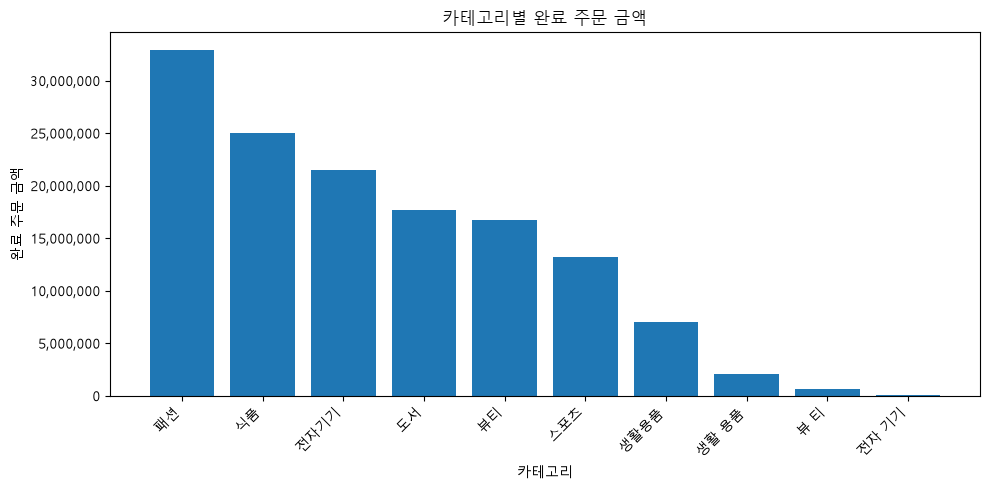

WindowsPath('g:/내 드라이브/dev_GD/llm-data-analysis-study/reports/figures/ch07_category_completed_amount_bar.png')

In [9]:
category_path = plot_category_sales(
    category_sales,
    FIGURE_DIR / "ch07_category_completed_amount_bar.png",
    show=True,
)
category_path

### 그래프 1 기록

- **관찰:** 카테고리별 completed 주문 금액은 패션 32,940,000원(24.05%)이 가장 높았으며, 식품 25,035,000원(18.28%), 전자기기 21,485,000원(15.69%) 순으로 나타났다. 상위 3개 카테고리가 전체 금액의 58.02%를 차지하였으며, 집계표와 막대그래프의 값이 일치하였다.
- **해석:** 완료 주문 금액이 일부 카테고리에 집중되어 있어 해당 카테고리를 상품 운영 및 마케팅 분석의 우선 대상으로 고려할 수 있다. 다만 금액 차이가 판매 수량이나 단가 중 어떤 요인에서 비롯되었는지는 추가 확인이 필요하다.
- **한계:** 주문 금액만으로 고객 선호도나 수익성을 판단할 수 없다. 또한 뷰티와 뷰 티처럼 동일한 의미의 카테고리가 서로 다른 항목으로 집계되어 있어 표기 표준화가 필요하다.
- **다음 질문:** 상위 카테고리의 판매 수량과 평균 판매 단가를 비교하고 등록 상품 수와 상위 상품의 금액 기여도를 함께 확인하면 카테고리별 금액 차이를 설명할 수 있는가?

## 4. 월별 완료 주문 금액 — 선그래프

시간 순서가 핵심인 질문이므로 선그래프를 사용합니다. 첫 달과 마지막 달이 완전한 한 달인지, 중간 월이 비어 있다면 실제 0인지 데이터 누락인지 확인합니다.

In [10]:
from src.visualization import plot_monthly_sales

monthly_sales[
    [
        "order_month",
        "completed_amount",
        "completed_order_count",
        "average_completed_order_amount",
    ]
]

,order_month,completed_amount,completed_order_count,average_completed_order_amount
0,2025-07,9479000.0,11,861727.0
1,2025-08,8892000.0,17,523059.0
2,2025-09,4519000.0,4,1129750.0
3,2025-10,12547000.0,17,738059.0
4,2025-11,9163000.0,16,572688.0
5,2025-12,8113000.0,12,676083.0
6,2026-01,7759000.0,8,969875.0
7,2026-02,7689000.0,12,640750.0
8,2026-03,7107000.0,13,546692.0
9,2026-04,11459000.0,14,818500.0


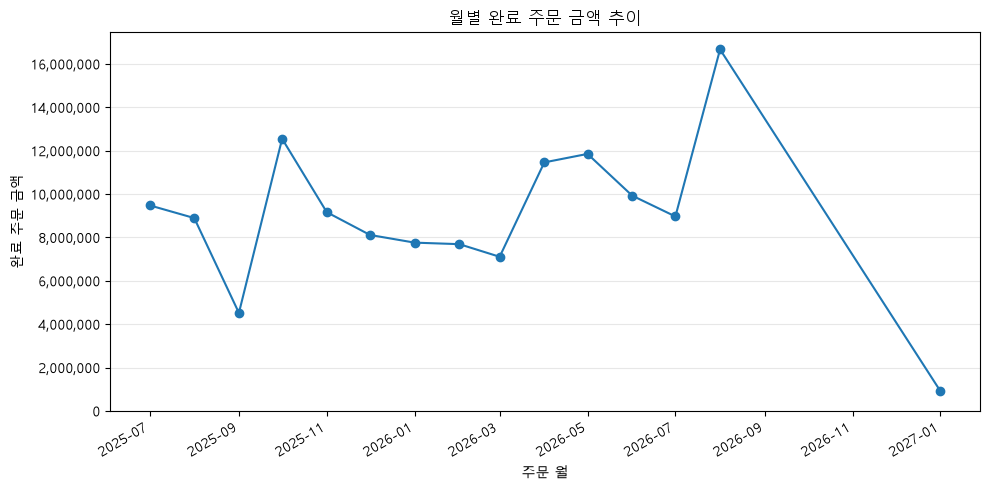

WindowsPath('g:/내 드라이브/dev_GD/llm-data-analysis-study/reports/figures/ch07_monthly_completed_amount_line.png')

In [11]:
monthly_path = plot_monthly_sales(
    monthly_sales,
    FIGURE_DIR / "ch07_monthly_completed_amount_line.png",
    show=True,
)
monthly_path

### 그래프 2 기록

- **관찰:** 월별 `completed` 주문 금액은 2026-08에 16,668,000원으로 가장 높았으며 해당 월의 완료 주문 수는 15건 평균 주문 금액은 1,111,200원이었다.  
2025-10은 주문 수가 17건으로 더 많았지만 총금액은 12,547,000원으로 낮았다. 월별 금액은 일정하게 증가하거나 감소하기보다 변동하는 양상을 보였다.

- **해석:** 월별 완료 주문 금액의 차이는 주문 수뿐 아니라 평균 주문 금액과도 관련이 있는 것으로 판단된다.  
특히 2026-08의 높은 금액은 주문 건수 증가만으로 설명하기 어렵고 상대적으로 높은 평균 주문 금액도 함께 고려해야 한다.

- **한계:** 월별 금액 변화만으로 프로모션이나 계절성 등의 원인을 단정할 수 없다. 또한 주문일이 누락된 완료 주문 상세 6행(1,903,000원)은 월별 집계에서 제외되었다. 2026-09부터 2026-12까지 관측 데이터가 없으므로 해당 기간의 실제 주문 금액이 0원이었다고 판단할 수 없으며, 이를 연결한 선그래프는 연속적인 감소 추세로 오해될 수 있다.

- **다음 질문:** 월별 주문 금액의 변동은 주문 수와 평균 주문 금액 중 어느 지표와 더 밀접하게 관련되어 있는가? 특히 2026-08의 금액 증가가 특정 카테고리나 고액 주문에 집중된 결과인지 추가로 확인할 필요가 있다.

## 5. 상품 가격 분포 — 히스토그램

상품 가격은 상품 마스터의 속성이므로 주문 상태와 무관하게 전체 상품을 봅니다. `bins` 값에 따라 모양이 달라질 수 있으므로 구간 수 하나만 보고 이상값을 확정하지 않습니다.

In [12]:
from src.visualization import plot_product_price_hist

products["price"].describe()

count    9.600000e+01
mean     2.048958e+05
std      1.011848e+06
min      5.000000e+03
25%      5.275000e+04
50%      9.450000e+04
75%      1.532500e+05
max      9.999999e+06
Name: price, dtype: float64

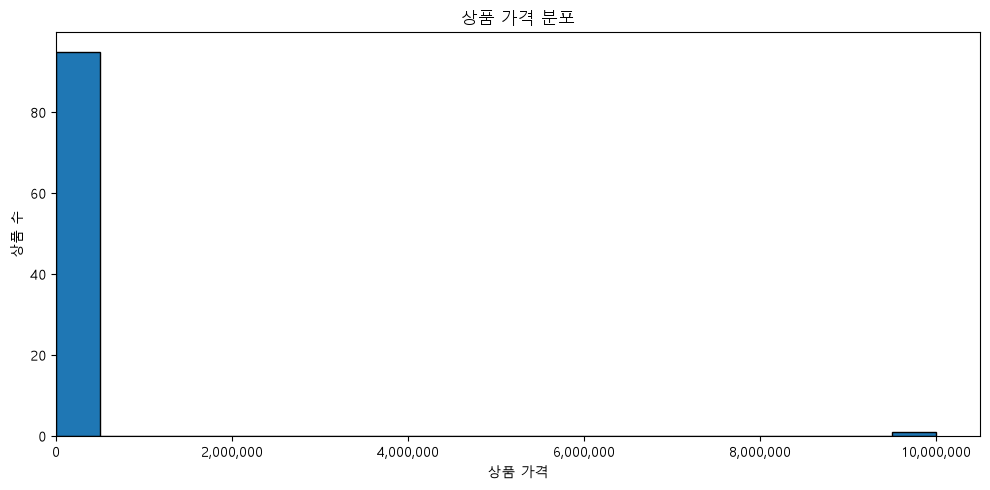

WindowsPath('g:/내 드라이브/dev_GD/llm-data-analysis-study/reports/figures/ch07_product_price_hist.png')

In [13]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=20,
)
price_hist_path

상품 가격 분포 — bins=10


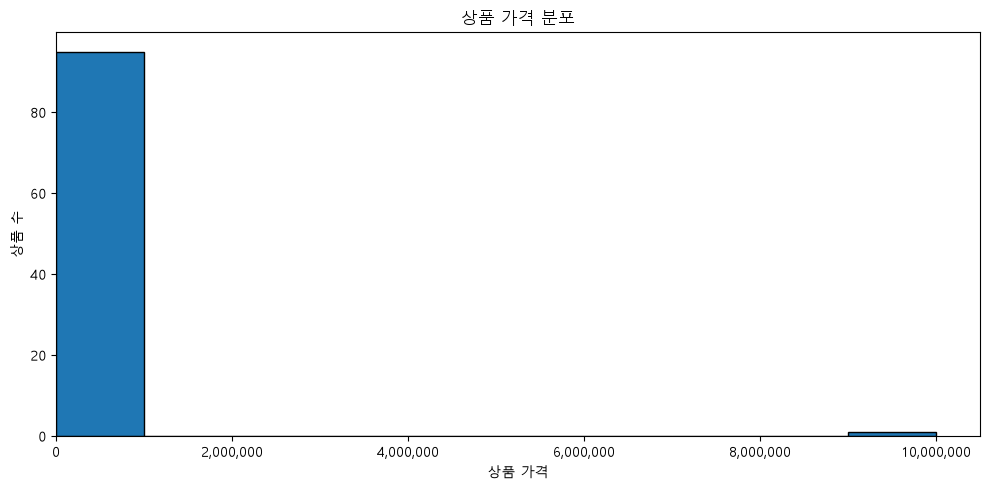

상품 가격 분포 — bins=20


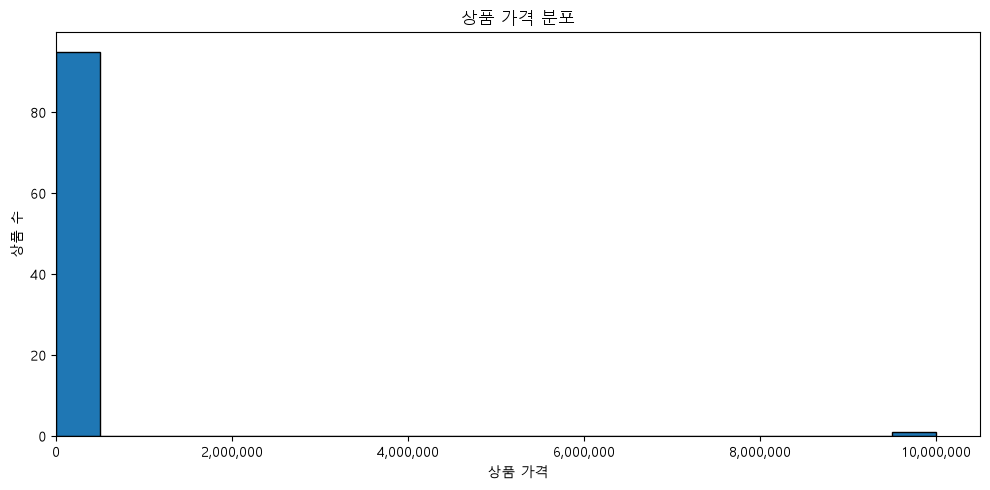

상품 가격 분포 — bins=30


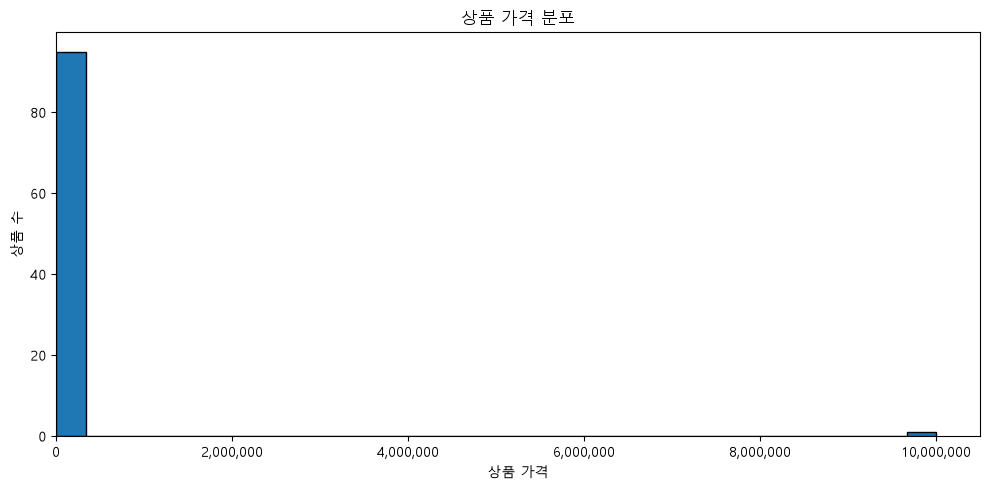

In [14]:

# 히스토그램 구간 수에 따른 분포 비교
for bins in [10, 20, 30]:
    print(f"상품 가격 분포 — bins={bins}")

    plot_product_price_hist(
        products,
        show=True,
        bins=bins,
    )


### bins 비교 실습

`bins=10`, `20`, `30`으로 바꾸어 같은 데이터가 어떻게 다르게 보이는지 비교합니다.

- 어떤 공통 패턴이 유지되는가?
  `bins=10`, `20`, `30` 모두 대부분의 상품이 낮은 가격 구간에 집중되어 있으며 9,999,999원의 극단값 1개가 다른 상품들과 멀리 떨어져 나타났다. 구간 수를 변경해도 오른쪽으로 긴 꼬리가 형성되는 분포 특성은 유지되었다.

- 어떤 인상은 bins 선택에 따라 달라지는가?
  `bins`가 증가할수록 각 구간의 폭이 좁아지지만 극단값으로 인해 전체 가격 범위가 넓게 설정되어 일반 상품들의 분포를 구분하기 어려웠다. 따라서 구간 수를 늘리는 것만으로는 분포 해석이 개선되지 않으며 일반 가격대를 확대한 보조 그래프가 필요하다고 판단하였다.

## 6. 상품 가격과 완료 주문 판매 수량 — 산점도

한 점은 상품 하나입니다. 관계가 보여도 **가격이 판매 수량의 원인**이라고 단정하지 않습니다.

In [15]:
from src.visualization import plot_price_quantity_scatter

product_sales[["price", "completed_quantity", "completed_amount"]].head(10)

,price,completed_quantity,completed_amount
70,183000.0,37.0,6771000.0
90,96000.0,70.0,6720000.0
91,187000.0,26.0,4862000.0
61,193000.0,22.0,4246000.0
50,152000.0,26.0,3952000.0
66,168000.0,21.0,3528000.0
45,171000.0,19.0,3249000.0
36,172000.0,17.0,2924000.0
47,183000.0,15.0,2745000.0
81,145000.0,18.0,2610000.0


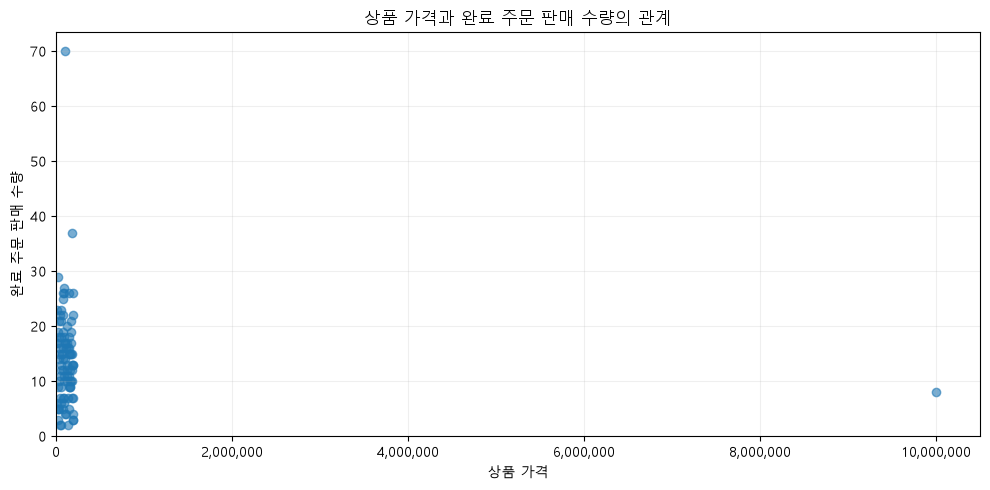

WindowsPath('g:/내 드라이브/dev_GD/llm-data-analysis-study/reports/figures/ch07_price_completed_quantity_scatter.png')

In [16]:
scatter_path = plot_price_quantity_scatter(
    product_sales,
    FIGURE_DIR / "ch07_price_completed_quantity_scatter.png",
    show=True,
)
scatter_path

### 그래프 3 기록

- **관찰:** 대부분의 상품 가격은 20만 원 이하에 분포하며 상품별 `completed` 판매 수량에는 차이가 나타났다. 특히 96,000원 상품은 70개, 183,000원 상품은 37개가 판매되었다. 또한 가격이 9,999,999원인 상품이 다른 상품들과 크게 떨어져 나타났다.
- **해석:** 상품 가격과 판매 수량 사이에 뚜렷한 선형 관계는 확인되지 않았다. 판매 수량은 가격 외에도 상품별 수요나 카테고리 등의 영향을 받을 가능성이 있다.
- **한계:** 산점도만으로 가격이 판매 수량에 미치는 인과관계를 판단할 수 없다. 또한 극단적으로 높은 가격의 상품으로 인해 일반 상품들의 분포가 압축되어 관계를 정확히 파악하기 어렵다. 재고, 할인, 상품 노출 및 판매 기간 정보도 포함되지 않았다.
- **다음 질문:** 일반적인 가격대의 상품만 확대하여 분석하고 카테고리별로 가격과 판매 수량의 관계를 비교하면 현재보다 뚜렷한 패턴이 나타나는가?

## 7. 완료 주문 구매 금액 상위 고객 — 익명 가로 막대그래프

공개 그래프에서는 고객 이름이나 원본 고객 ID를 직접 표시하지 않고 **순위 기반 익명 라벨**을 사용합니다. Top 10은 전체 고객 분포가 아니라 일부 고객만 보여 줍니다.

In [17]:
from src.visualization import plot_top_customers

customer_sales[
    ["customer_id", "completed_order_count", "completed_amount", "average_completed_order_amount"]
].head(10)

,customer_id,completed_order_count,completed_amount,average_completed_order_amount
1,3,3,6702000.0,2234000.0
7,14,4,5122000.0,1280500.0
57,90,3,4311000.0,1437000.0
47,65,6,3977000.0,662833.0
66,104,2,3966000.0,1983000.0
59,93,4,3845000.0,961250.0
11,20,4,3808000.0,952000.0
27,38,4,3656000.0,914000.0
19,28,4,3201000.0,800250.0
55,85,4,2832000.0,708000.0


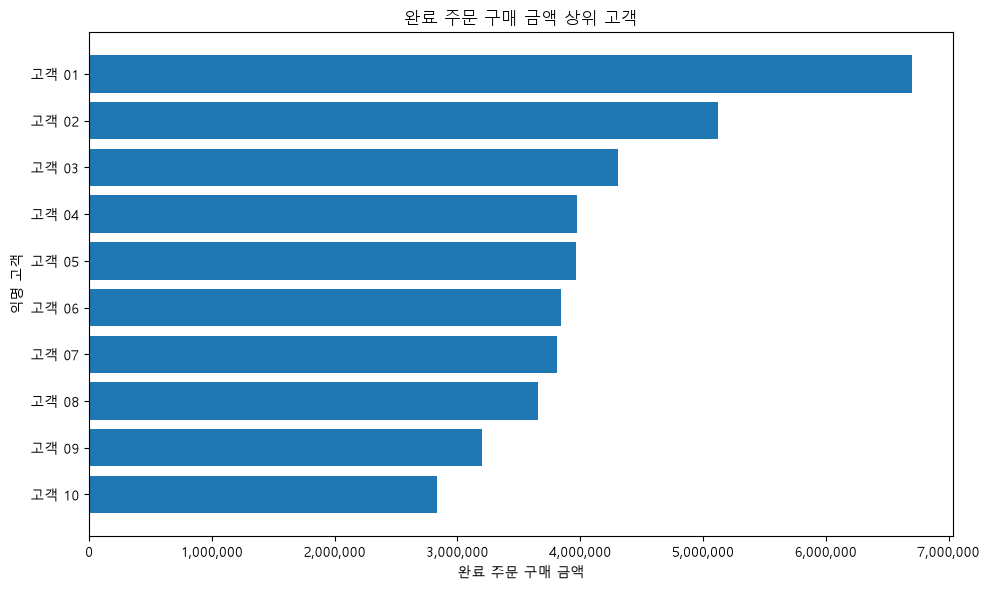

WindowsPath('g:/내 드라이브/dev_GD/llm-data-analysis-study/reports/figures/ch07_top_customers_anonymized_barh.png')

In [18]:
top_customer_path = plot_top_customers(
    customer_sales,
    FIGURE_DIR / "ch07_top_customers_anonymized_barh.png",
    show=True,
    top_n=10,
)
top_customer_path

### 해석 주의

구매 금액이 높다고 바로 '충성 고객'이라고 부르지 않습니다.

- 반복 주문 횟수는 많은가? 상위 10명의 `completed` 주문 수는 2~6건으로 나타났다. 고객 04는 6건으로 가장 많았으나, 구매 금액은 고객 01보다 낮았다.
- 한 번의 큰 주문 때문인가? 고객 01은 3건의 주문으로 6,702,000원을 구매하였다. 다만 현재 집계표는 주문별 금액을 보여 주지 않으므로 특정 고액 주문의 영향인지는 추가 확인이 필요하다.
- 평균 주문 금액은 어떤가? 고객 01의 평균 주문 금액은 2,234,000원으로 고객 04의 662,833원보다 높았다. 누적 구매 금액에는 주문 횟수뿐 아니라 건당 구매 금액도 영향을 미치는 것으로 판단된다.
- 분석 기간이 충분한가? 현재 결과는 전체 고객 중 구매 금액 상위 10명만 보여 주며 고객별 구매 시점과 재구매 간격을 검증하지 않았다. 따라서 구매 금액이 높다는 이유만으로 충성 고객이라고 판단하기 어렵다.

## 8. 전체 주문 상태 — 막대그래프

이 그래프만 전체 주문을 사용합니다. 상태별 규모는 보여 주지만 취소·환불의 원인을 설명하지 않습니다.

In [19]:
from src.visualization import plot_order_status

order_status

,order_status,order_count
0,completed,179
1,cancelled,62
2,refunded,57


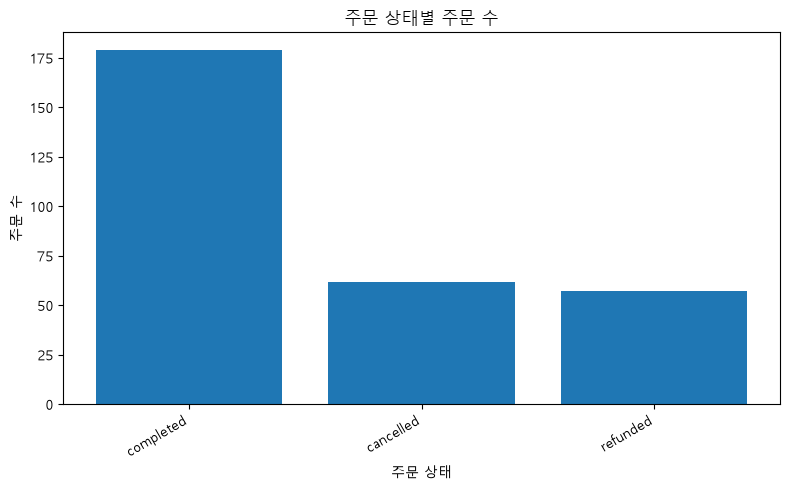

WindowsPath('g:/내 드라이브/dev_GD/llm-data-analysis-study/reports/figures/ch07_order_status_bar.png')

In [20]:
order_status_path = plot_order_status(
    order_status,
    FIGURE_DIR / "ch07_order_status_bar.png",
    show=True,
)
order_status_path

## 9. 그래프와 숫자를 교차 검증합니다

대표 그래프 3개 이상에 대해 다음을 확인합니다.

```text
그래프에 표시된 값
=
그래프 원본 집계표의 값

- 카테고리별 막대그래프: `completed` 주문 금액 합계 136,949,000원으로 집계표와 일치
- 월별 선그래프: 유효 날짜 기준 금액 135,046,000원으로 집계표와 일치
- 가격·판매 수량 산점도: 상품별 가격과 `completed_quantity`가 원본 집계표의 값과 일치 

```

또한 다음을 점검합니다.

- 축 이름과 단위가 맞는가? 각 그래프에 금액(원), 판매 수량(개) 등 분석 지표에 맞는 축 이름과 단위가 표시됨.
- 범주 정렬과 날짜 정렬이 맞는가? 카테고리는 금액 내림차순, 월별 데이터는 시간순으로 정렬됨.
- 막대그래프 값 축이 불필요하게 잘리지 않았는가? 막대그래프의 금액 축이 0부터 시작하여 차이를 과장하지 않음.
- 제목이 실제 분석 범위를 반영하는가? 각 그래프의 제목이 실제 분석 대상과 지표를 설명함.
- 데이터가 없는 구간을 임의로 0으로 만들지 않았는가? 2026-09~2026-12에는 관측 데이터가 없으며 이를 실제 주문 금액 0원으로 해석하지 않음. 현재 선그래프가 공백 구간을 연결한다는 한계가 있음.


## 10. 공통 함수로 전체 그래프와 보고서를 다시 생성합니다

Notebook에서 개별 그래프를 이해한 뒤 공통 함수를 사용해 같은 결과를 재현합니다.

In [22]:
from src.visualization import (
    build_visualization_report,
    create_all_figures,
    create_visualization_summary,
)

saved_figures = create_all_figures(viz_data, FIGURE_DIR, show=False)
summary = create_visualization_summary()

summary_path = REPORT_DIR / "ch07_visualization_summary.md"
summary_path.write_text(
    build_visualization_report(summary),
    encoding="utf-8",
)

print("생성 파일")
for path in saved_figures:
    print("-", path)

print("요약 보고서:", summary_path)
summary

생성 파일
- g:\내 드라이브\dev_GD\llm-data-analysis-study\reports\figures\ch07_category_completed_amount_bar.png
- g:\내 드라이브\dev_GD\llm-data-analysis-study\reports\figures\ch07_monthly_completed_amount_line.png
- g:\내 드라이브\dev_GD\llm-data-analysis-study\reports\figures\ch07_product_price_hist.png
- g:\내 드라이브\dev_GD\llm-data-analysis-study\reports\figures\ch07_price_completed_quantity_scatter.png
- g:\내 드라이브\dev_GD\llm-data-analysis-study\reports\figures\ch07_top_customers_anonymized_barh.png
- g:\내 드라이브\dev_GD\llm-data-analysis-study\reports\figures\ch07_order_status_bar.png
요약 보고서: g:\내 드라이브\dev_GD\llm-data-analysis-study\reports\ch07_visualization_summary.md


,chart,question,scope,interpretation_point,file_name
0,카테고리별 완료 주문 금액,카테고리별 완료 주문 금액은 어떻게 다른가?,completed orders,금액 차이는 수량·단가 등 추가 지표로 확인,ch07_category_completed_amount_bar.png
1,월별 완료 주문 금액,월별 완료 주문 금액은 어떻게 변하는가?,completed orders + valid order_date,증감은 관찰이며 원인은 추가 데이터 필요,ch07_monthly_completed_amount_line.png
2,상품 가격 분포,상품 가격은 어떤 구간에 몰려 있는가?,product master,상품 구성 분포이며 판매 선호를 의미하지 않음,ch07_product_price_hist.png
3,상품 가격과 완료 주문 판매 수량,상품 가격과 완료 주문 판매 수량은 어떤 패턴을 보이는가?,completed orders aggregated by product,관계는 인과를 의미하지 않음,ch07_price_completed_quantity_scatter.png
4,완료 주문 구매 금액 상위 고객,완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가?,completed orders aggregated by customer,Top N이며 충성도를 자동 의미하지 않음,ch07_top_customers_anonymized_barh.png
5,주문 상태별 주문 수,주문 상태별 주문 수는 어떻게 다른가?,all orders,상태 분포만으로 취소·환불 원인을 알 수 없음,ch07_order_status_bar.png


## 11. Chapter 07 최종 판단

아래 내용을 직접 작성합니다.

### 가장 중요한 그래프 1개와 이유
가장 중요한 그래프는 **카테고리별 완료 주문 금액 막대그래프**라고 판단하였다. 카테고리별 금액 규모와 비중을 직관적으로 비교할 수 있으며 상품 운영 및 마케팅 분석의 우선순위를 결정하는 데 활용할 수 있기 때문이다.

### 그래프에서 직접 확인한 사실
참조관계 검증을 통과한 `completed` 주문 금액 합계는 136,949,000원이었다. 이 중 패션이 32,940,000원(24.05%)으로 가장 높았고 식품 25,035,000원(18.28%), 전자기기 21,485,000원(15.69%) 순이었다. 상위 3개 카테고리의 금액 비중은 58.02%였으며 집계표와 그래프의 수치가 일치함을 확인하였다.

### 내가 해석한 내용
완료 주문 금액이 일부 카테고리에 집중되어 있으므로 해당 카테고리를 중심으로 상품별 판매 기여도와 구매 특성을 추가 분석할 필요가 있다고 판단하였다. 다만 금액 차이가 판매 수량, 단가 또는 일부 고액 거래 중 어떤 요인에 의해 발생했는지는 구분해서 확인해야 한다.

### 그래프만으로 말할 수 없는 것
카테고리별 주문 금액만으로 고객 선호도, 상품의 수익성 또는 마케팅 효과를 단정할 수 없다. 또한 이번 분석은 PK/FK 불일치 데이터를 제외한 범위이므로 Chapter 06의 전체 분석 결과와 차이가 있다. `뷰티`와 `뷰 티`처럼 카테고리 표기가 일치하지 않는 문제도 남아 있다.

### 오해를 줄이기 위해 수정하거나 확인한 요소
- 축: 막대그래프의 금액 축이 0부터 시작하는 것을 확인하였다. 반면 히스토그램과 산점도에서는 극단적인 상품 가격으로 인해 일반 가격대의 분포가 압축되는 한계가 있었다.
- 단위: 금액은 원, 판매 수량은 개, 주문 수는 건을 기준으로 해석하였으며 축에 단위를 명시하면 가독성을 높일 수 있다고 판단하였다.
- 정렬: 카테고리별 금액은 내림차순 월별 금액은 시간순으로 정렬되어 있음을 확인하였다.
- 범위: 금액 분석은 `completed` 주문을 기준으로 수행하였다. 월별 집계에서는 날짜 결측 6행(1,903,000원)을 제외하였으며 2026-09~2026-12의 관측 공백이 선으로 연결되어 연속적인 감소 추세처럼 보일 수 있다는 문제를 확인하였다.
- 개인정보: 상위 고객 그래프는 실제 이름이나 고객 ID 대신 익명 라벨을 사용하여 불필요한 개인정보 노출을 방지하였다.

### 다음 분석에서 확인하고 싶은 질문  
카테고리별 완료 주문 금액 차이는 판매 수량과 평균 판매 단가 중 어떤 요인의 영향을 더 크게 받는가?  
이를 확인하기 위해 카테고리 표기를 통일한 후 판매 수량, 평균 단가, 등록 상품 수 및 상위 상품의 금액 기여도를 비교하고자 한다.

---

## 완료 체크

- [O] 질문을 그래프보다 먼저 정했습니다.
- [O] 금액성 그래프에 `completed` 주문 범위를 적용했습니다.
- [O] 집계 검증표의 `passed`를 확인했습니다.
- [O] 대표 그래프 3개 이상을 만들었습니다.
- [O] 그래프와 원본 집계값을 교차 확인했습니다.
- [O] 축·단위·정렬·범위를 확인했습니다.
- [O] 관계를 원인으로 단정하지 않았습니다.
- [O] 고객 그래프에서 개인정보를 직접 노출하지 않았습니다.
- [O] 그래프별 관찰·해석·한계·다음 질문을 작성했습니다.
- [O] `reports/figures`와 요약 보고서가 재생성되는지 확인했습니다.

다음 Chapter 08에서는 전처리, EDA, 시각화와 보고서를 하나의 작은 분석 프로젝트로 연결합니다.

# Chapter 07 답안 양식. 그래프로 데이터의 이야기를 보여주기

> 이 내용을 `chapter07.ipynb`의 Markdown 셀로 작성합니다.

## 제출 정보
- 이름: 김희철
- GitHub ID: KHeeCheol
- 작성일: 2026-10-20
- 최종 Notebook URL: https://github.com/KHeeCheol/llm-data-analysis-study/blob/main/notebooks/chapter07.ipynb

## 1. 시각화 질문과 그래프 선택

| 질문 | 선택한 그래프 | 선택 이유 |
|---|---|---|
| 카테고리별 `completed` 주문 금액은 어떻게 다른가? | 막대그래프 | 카테고리별 금액 규모와 비중을 비교하기 적합하다. |
| 월별 `completed` 주문 금액은 어떻게 변하는가? | 선그래프 | 시간에 따른 금액 변화와 변동 구간을 확인할 수 있다. |
| 상품 가격과 `completed` 판매 수량 사이에는 어떤 패턴이 있는가? | 산점도 | 두 숫자형 변수의 관계와 극단값을 탐색하기 적합하다. |

금액 관련 분석은 Chapter 05의 clean CSV에서 PK/FK 참조관계가 검증된 데이터만을 대상으로 하였다. 기존 `data/processed`는 보존하고, Chapter 07 전용 데이터를 `data/ch07_processed`에 별도로 생성하였다.

## 2. 대표 그래프 1
![대표 그래프 1](images/ch07_category_completed_amount_bar.png)

### 원본 집계값

`completed` 주문 기준 금액 합계는 136,949,000원이다.

| 카테고리 | 완료 주문 금액 | 금액 비중 |
|---|---:|---:|
| 패션 | 32,940,000원 | 24.05% |
| 식품 | 25,035,000원 | 18.28% |
| 전자기기 | 21,485,000원 | 15.69% |

상위 3개 카테고리의 합계는 79,460,000원으로 전체 금액의 58.02%를 차지하였다. 카테고리별 집계 합계는 원본 `completed` 금액 136,949,000원과 일치하였다.

### 결과 관찰

패션의 완료 주문 금액이 가장 높았으며 식품과 전자기기가 뒤를 이었다. 상위 3개 카테고리가 전체 금액의 절반 이상을 차지하였고 집계표와 막대그래프의 값 및 정렬 순서가 일치하였다.

### 나의 해석과 판단
완료 주문 금액이 일부 카테고리에 집중되어 있어 해당 카테고리를 우선 분석할 필요가 있다고 판단하였다. 다만 금액 차이가 판매 수량, 상품 단가 또는 특정 고액 거래 중 어떤 요인에서 발생했는지는 구분해서 확인해야 한다.

### 업무·분석적 의미
카테고리별 금액 비중은 상품 운영 및 마케팅 분석의 우선순위를 설정하는 기초 자료로 활용할 수 있다. 특히 상위 카테고리에서 상품별 금액 기여도를 분석하면 핵심 상품군을 구체화할 수 있다.
### 한계와 추가 확인 사항
주문 금액만으로 고객 선호도나 수익성을 판단할 수 없다. 또한 `뷰티`와 `뷰 티`, `생활용품`과 `생활 용품`처럼 동일한 의미의 카테고리가 별도로 집계되어 있다.

향후 카테고리 표기를 통일하고 판매 수량·평균 단가·등록 상품 수와 상위 상품의 금액 기여도를 함께 비교할 필요가 있다.

## 3. 대표 그래프 2
![대표 그래프 2](images/ch07_monthly_completed_amount_line.png)

### 원본 집계값
유효한 주문일을 가진 `completed` 주문 상세의 월별 금액 합계는 135,046,000원이다.

주요 월별 집계 결과는 다음과 같다.

| 주문 월 | 완료 주문 금액 | 완료 주문 수 | 평균 주문 금액 |
|---|---:|---:|---:|
| 2025-10 | 12,547,000원 | 17건 | 738,059원 |
| 2026-05 | 11,850,000원 | 12건 | 987,500원 |
| 2026-08 | 16,668,000원 | 15건 | 1,111,200원 |
| 2027-01 | 909,000원 | 1건 | 909,000원 |

주문일이 누락된 `completed` 상세 6행의 금액은 1,903,000원이며 이를 월별 합계에 더하면 전체 금액 136,949,000원과 일치한다.
### 결과 관찰
2026-08의 완료 주문 금액이 16,668,000원으로 가장 높았다. 2025-10은 완료 주문 수가 17건으로 더 많았지만 평균 주문 금액이 낮아 총금액은 12,547,000원으로 나타났다. 전체 기간에서 월별 금액은 일정한 증가 또는 감소보다는 변동하는 양상을 보였다.

### 나의 해석과 판단

월별 완료 주문 금액은 주문 건수와 평균 주문 금액의 영향을 함께 받는 것으로 판단하였다. 특히 2026-08의 높은 금액은 주문 건수만으로 설명하기 어려우며 상대적으로 높은 평균 주문 금액도 함께 고려할 필요가 있다.

### 업무·분석적 의미

월별 주문 수와 평균 주문 금액을 구분하여 분석하면 금액 변동의 주요 요인을 탐색할 수 있다. 금액이 높았던 기간의 상품 카테고리 및 고액 주문 비중을 추가 확인하면 마케팅 및 상품 운영에 활용할 수 있는 분석 질문을 도출할 수 있다.

### 한계와 추가 확인 사항

월별 금액 변화만으로 프로모션이나 계절성의 영향을 단정할 수 없다.

또한 2026-09부터 2026-12까지 관측 데이터가 없으므로 실제 주문이 0건이었다고 해석할 수 없다. 현재 선그래프는 해당 공백 구간을 직선으로 연결하여 지속적인 감소 추세처럼 보일 수 있다는 한계가 있다.

향후 데이터 수집 기간의 연속성을 확인하고, 월별 주문 수·평균 주문 금액·카테고리 구성을 함께 비교할 필요가 있다.

## 4. 대표 그래프 3
![대표 그래프 3](images/ch07_price_completed_quantity_scatter.png)

### 원본 집계값

한 점은 상품 하나를 의미하며, 상품 마스터의 `price`와 상품별 `completed_quantity`를 사용하였다.

실제 집계값 중 대표 사례는 다음과 같다.

| 상품 가격 | 완료 주문 판매 수량 | 완료 주문 금액 |
|---|---:|---:|
| 96,000원 | 70개 | 6,720,000원 |
| 183,000원 | 37개 | 6,771,000원 |
| 187,000원 | 26개 | 4,862,000원 |
| 193,000원 | 22개 | 4,246,000원 |

또한 `price=9,999,999`인 상품이 일반적인 가격대와 크게 떨어져 나타났다.

### 결과 관찰

대부분의 상품 가격은 20만 원 이하에 분포하였으며 상품별 완료 주문 판매 수량에는 상당한 차이가 있었다. 산점도에서 가격과 판매 수량 사이의 뚜렷한 선형 관계는 확인되지 않았다.

특히 9,999,999원의 극단적인 가격으로 인해 다른 상품들이 그래프 왼쪽에 압축되어 나타났다.

### 나의 해석과 판단

현재 데이터에서는 상품 가격만으로 판매 수량의 차이를 설명하기 어렵다고 판단하였다. 가격뿐 아니라 상품 카테고리, 수요 및 판매 조건 등 다른 요인이 영향을 미쳤을 가능성이 있다.

### 업무·분석적 의미

상품 가격과 판매 수량의 관계를 분석하면 가격대별 상품 운영 전략을 검토하는 데 활용할 수 있다. 특히 카테고리별로 가격과 판매 수량의 패턴을 분리하면 상품 구성 및 판매 특성에 관한 추가 분석이 가능하다.

### 한계와 추가 확인 사항

산점도에서 관찰되는 관계만으로 가격이 판매량에 미치는 인과관계를 판단할 수 없다. 또한 재고, 할인, 상품 노출, 판매 기간 등의 정보가 포함되어 있지 않다.

극단적인 가격은 실제 오류인지 확인되지 않았으므로 임의로 제거하지 않았다. 향후 일반 가격대를 확대한 보조 그래프를 작성하고, 카테고리별 가격과 판매 수량의 관계를 비교할 필요가 있다.

## 5. 그래프 정확성 점검
- [O] 그래프 값과 집계표 값 일치
- [O] 축 이름 확인
- [O] 단위 확인
- [O] 범례 확인
- [O] 날짜 정렬 확인
- [O] 과장될 수 있는 축 범위 확인
- [O] 제목이 분석 범위를 정확히 표현

### 내가 발견한 시각화 위험 또는 개선점
1. 카테고리 표기 불일치

- 문제: 동일한 의미의 카테고리가 서로 다른 항목으로 표시되었다.
- 위험: 카테고리별 금액 비중을 정확히 비교하기 어렵다.
- 개선점: 카테고리 표기를 표준화한 후 집계값과 그래프를 재검증할 필요가 있다.

2. 월별 관측 공백

- 문제: 2026-09~2026-12의 관측 데이터가 없지만 선그래프에서는 이전·이후 월이 연결되어 있다.
- 위험: 실제로 관측되지 않은 기간을 지속적인 감소 추세로 오해할 수 있다.
- 개선점: 데이터가 없는 기간의 선 연결을 끊고, 관측 공백을 명확하게 표시할 필요가 있다.

3. 상품 가격 극단값

- 문제: 9,999,999원의 극단적인 가격으로 인해 히스토그램과 산점도에서 일반 가격대가 압축되었다.
- 위험: 대부분의 상품 가격 분포와 관계를 파악하기 어렵다.
- 개선점: 원본 데이터를 유지하면서 일반 가격대를 확대한 보조 그래프를 추가하는 방법이 적절하다.

위 사항들은 발견한 개선점으로 기록하였으며 원본 데이터를 임의로 수정하지 않았다.

## 6. Chapter 07 최종 판단
### 가장 중요한 그래프 1개와 이유
가장 중요한 그래프는 **카테고리별 완료 주문 금액 막대그래프**라고 판단하였다.

카테고리별 금액 규모와 비중을 직관적으로 비교할 수 있으며 상품 운영 및 마케팅 분석의 우선순위를 설정하는 데 활용할 수 있기 때문이다.

### 그래프가 보여 준 사실

참조관계 검증을 통과한 `completed` 주문 금액은 136,949,000원이었다. 패션이 32,940,000원(24.05%)으로 가장 높았으며 식품과 전자기기가 뒤를 이었다.

상위 3개 카테고리의 금액 비중은 58.02%였으며 집계표와 그래프의 수치가 일치함을 확인하였다.

### 그래프만으로 말할 수 없는 것

완료 주문 금액이 높다는 사실만으로 고객 선호도, 상품의 수익성 또는 마케팅 효과를 단정할 수 없다.  
또한 이번 Chapter 07에서는 PK/FK 참조관계가 성립하지 않는 주문 및 상세 데이터를 제외하였기 때문에 Chapter 06과 분석 범위가 다르다. 전체 데이터에서 어떤 정보를 제외했는지도 결과 해석에 반영해야 한다.

### 다음 분석에서 확인할 질문

**카테고리별 완료 주문 금액 차이는 판매 수량, 평균 단가 및 상위 상품의 금액 기여도 중 어떤 요인과 더 밀접하게 관련되어 있는가?**

이를 확인하기 위해 카테고리 표기를 통일한 후 판매 수량, 평균 판매 단가, 상품 수 및 상위 상품의 금액 기여도를 비교하고자 한다.

## 최종 체크
- [O] 그래프와 수치를 교차 검증했습니다.
- [O] 관찰과 해석을 구분했습니다.
- [O] 업무적 의미와 한계를 작성했습니다.
- [O] 최종 Notebook URL을 제출합니다.